# Vorhersage mit Azure AutoML Endpoint

In diesem Notebook wird gezeigt, wie über einen **bereitgestellten Azure AutoML Endpoint**
der 30-jährige US-Hypothekarzins für die nächsten 12 Wochen vorhergesagt werden kann. Die Ergebnisse werden anschliessend grafisch dargestellt.

**Ablauf:**
1. Aufbau der Anfrage (Payload mit Features).
2. Absetzen der Anfrage gegen den Endpoint.
3. Verarbeitung der Ergebnisse.
4. Visualisierung der Vorhersagen in einem Plot.

In [1]:
# Benötigte Bibliotheken importieren
import urllib.request
import urllib.error
import ssl
import certifi
import json
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Farben für alle Plots: Historie blau, Vorhersage orange
FARBE_HISTORIE = "#1f77b4"
FARBE_PROGNOSE = "#ff7f0e"

## Historische Daten laden

Die wöchentlichen Daten seit 2000 (Hypothekarzins und Einflussfaktoren, jeweils Donnerstag) werden aus `Daten/hypozins_usa.csv` geladen.

In [2]:
# CSV mit historischen Daten laden (Pfad relativ zum Ordner Code/)
df_hist = pd.read_csv("../Daten/hypozins_usa.csv")

# Datumsspalte in Datumsformat umwandeln
df_hist["datum"] = pd.to_datetime(df_hist["datum"])

df_hist.info()

<class 'pandas.DataFrame'>
RangeIndex: 1402 entries, 0 to 1401
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   datum              1402 non-null   datetime64[us]
 1   hypozins_30j       1402 non-null   float64       
 2   rendite_10j        1402 non-null   float64       
 3   leitzins           1402 non-null   float64       
 4   inflation          1402 non-null   float64       
 5   arbeitslosenquote  1402 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 65.8 KB


## Schritt 1: Endpoint-URL und Schlüssel

Jeder Azure-Endpoint hat eine eigene URL und einen API-Schlüssel (Key).
- Die URL wird benötigt, um die Anfrage an die richtige Stelle zu senden.
- Der Key dient zur Authentifizierung.

Hinweis: Der Key darf niemals öffentlich geteilt werden. Er steht deshalb nicht im Notebook, sondern wird aus der Datei `endpoint_key.txt` gelesen, die über `.gitignore` von Git ausgeschlossen ist.

In [3]:
# Endpoint-URL
url = "https://hypozins-endpoint.switzerlandnorth.inference.ml.azure.com/score"

# API-Key aus Datei lesen (wird nie ausgegeben)
with open("endpoint_key.txt", encoding="utf-8-sig") as datei:
    api_key = datei.read().strip()
if not api_key:
    raise ValueError("Kein API-Key gefunden: bitte den Key in Code/endpoint_key.txt einfügen.")
if not api_key.isascii() or any(zeichen.isspace() for zeichen in api_key):
    raise ValueError("Ungültiger API-Key: endpoint_key.txt darf nur den Key auf einer einzigen Zeile enthalten.")

headers = {
    "Content-Type": "application/json",
    "Authorization": ("Bearer " + api_key)
}

## Schritt 2: Payload erstellen

Die Payload enthält die Daten, die an den Endpoint gesendet werden.  
Vorhergesagt werden die **12 Wochen nach dem letzten Datum der Historie** (jeweils Donnerstag, +7 Tage). Da die zukünftigen Werte der Einflussfaktoren nicht bekannt sind, bleiben Rendite, Leitzins, Inflation und Arbeitslosenquote auf dem **letzten bekannten Wert** (Annahme: Stand von heute).

Jede Zeile in `data` steht für eine Woche mit allen benötigten Eingabe-Features, ohne die Zielspalte `hypozins_30j`.

In [4]:
# Letzte bekannte Woche aus der Historie
last_row = df_hist.iloc[-1]

# 12 Wochen nach dem letzten Datum (jeweils +7 Tage)
future = pd.DataFrame({
    "datum": pd.date_range(last_row["datum"] + pd.Timedelta(days=7), periods=12, freq="7D")
})

# Einflussfaktoren auf dem letzten bekannten Wert halten
for col in ["rendite_10j", "leitzins", "inflation", "arbeitslosenquote"]:
    future[col] = last_row[col]

# datum in String umwandeln (Format JJJJ-MM-TT)
future["datum"] = future["datum"].dt.strftime("%Y-%m-%d")

# Payload bauen
data = {
    "input_data": {
        "columns": list(future.columns),
        "index": list(range(len(future))),
        "data": future.values.tolist()
    }
}

future

,datum,rendite_10j,leitzins,inflation,arbeitslosenquote
0,2026-11-19,4.96,3.88,3.95,4.1
1,2026-11-26,4.96,3.88,3.95,4.1
2,2026-12-03,4.96,3.88,3.95,4.1
3,2026-12-10,4.96,3.88,3.95,4.1
4,2026-12-17,4.96,3.88,3.95,4.1
5,2026-12-24,4.96,3.88,3.95,4.1
6,2026-12-31,4.96,3.88,3.95,4.1
7,2027-01-07,4.96,3.88,3.95,4.1
8,2027-01-14,4.96,3.88,3.95,4.1
9,2027-01-21,4.96,3.88,3.95,4.1


## Schritt 3: Anfrage an den Endpoint senden und Ergebnisse visualisieren

Die Daten werden an den Endpoint gesendet. Die Vorhersagen werden als JSON zurückgegeben,
in einen Pandas DataFrame umgewandelt, als Tabelle angezeigt und anschliessend als Zeitreihe geplottet. Bei einem Fehler werden der HTTP-Status und die Fehlermeldung ausgegeben.

,datum,prognose_hypozins_30j
0,2026-11-19,7.17
1,2026-11-26,7.17
2,2026-12-03,7.17
3,2026-12-10,7.17
4,2026-12-17,7.17
5,2026-12-24,7.17
6,2026-12-31,7.16
7,2027-01-07,7.16
8,2027-01-14,7.16
9,2027-01-21,7.16


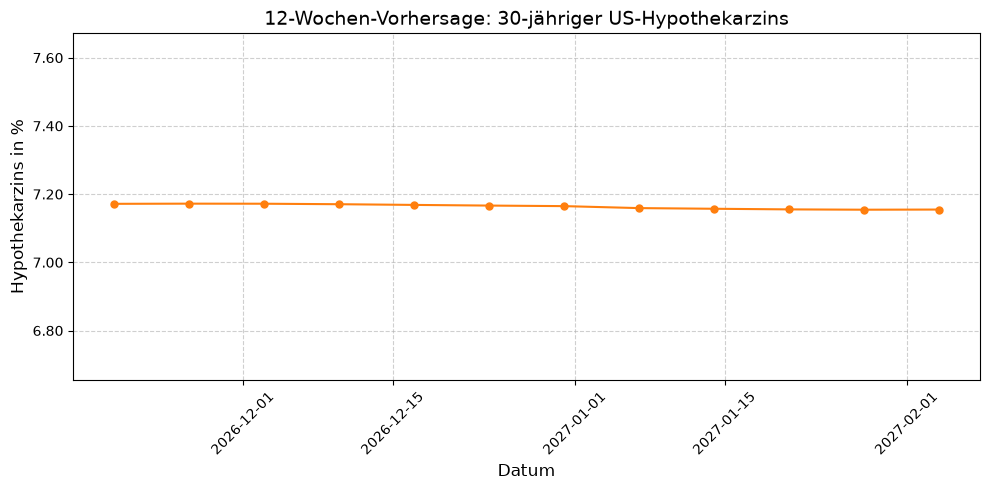

In [5]:
body = str.encode(json.dumps(data))
req = urllib.request.Request(url, body, headers)

# Zertifikate aus certifi verwenden (Python von python.org bringt unter macOS keine eigenen mit)
ssl_context = ssl.create_default_context(cafile=certifi.where())

try:
    response = urllib.request.urlopen(req, context=ssl_context)
except urllib.error.HTTPError as error:
    # Bei einem Fehler HTTP-Status und Fehlermeldung ausgeben
    print("Anfrage fehlgeschlagen, HTTP-Status:", error.code, error.reason)
    print(error.read().decode("utf-8", "ignore"))
    raise RuntimeError("Der Endpoint hat keine Vorhersage geliefert.") from None
except urllib.error.URLError as error:
    # Endpoint nicht erreichbar (z.B. keine Internetverbindung)
    print("Endpoint nicht erreichbar:", error.reason)
    raise RuntimeError("Der Endpoint konnte nicht erreicht werden.") from None
result = response.read()

# Vorhersagen in Liste umwandeln
preds = json.loads(result.decode("utf-8"))

# DataFrame bauen (Datum direkt aus Payload nehmen)
dates = [row[0] for row in data["input_data"]["data"]]
df = pd.DataFrame({"datum": pd.to_datetime(dates), "prognose_hypozins_30j": preds})

# Tabelle der Vorhersagen
display(df.round({"prognose_hypozins_30j": 2}))

# Plot der reinen Vorhersage
plt.figure(figsize=(10,5))
plt.plot(df["datum"], df["prognose_hypozins_30j"], linestyle="-", linewidth=1.5, marker="o", markersize=5, color=FARBE_PROGNOSE)
plt.title("12-Wochen-Vorhersage: 30-jähriger US-Hypothekarzins", fontsize=14)
plt.xlabel("Datum", fontsize=12)
plt.ylabel("Hypothekarzins in %", fontsize=12)
# Ehrlicher y-Bereich: Prognose +/- 0.5 Prozentpunkte, Achse mit 2 Nachkommastellen
plt.ylim(df["prognose_hypozins_30j"].min() - 0.5, df["prognose_hypozins_30j"].max() + 0.5)
plt.gca().yaxis.set_major_formatter("{x:.2f}")
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Schritt 4: Historie und Vorhersagen kombinieren und darstellen

Die historischen Daten werden auf die letzten 3 Jahre vor Beginn der Vorhersage reduziert und die Vorhersagen an das Ende der Historie angefügt. Anschliessend erscheinen beide Zeitreihen gemeinsam im Plot, sodass der direkte Vergleich zwischen Vergangenheit und Prognose möglich wird.

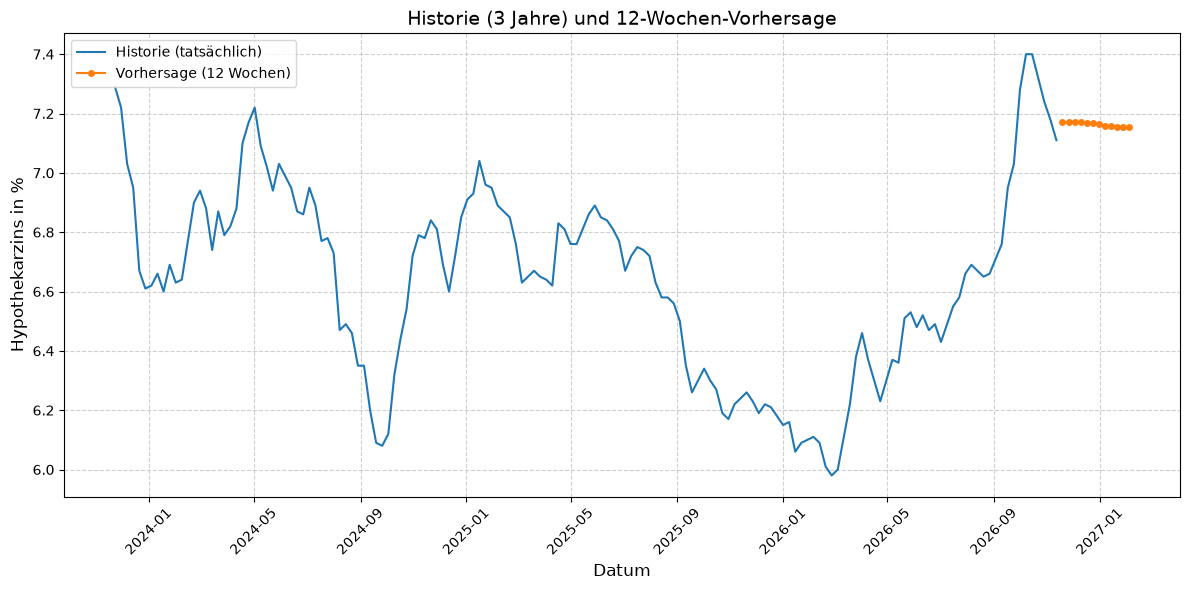

In [6]:
# Historie: letzte 3 Jahre vor Beginn der Vorhersage
hist_window = pd.DateOffset(years=3)
first_forecast_date = df["datum"].min()
df_hist_plot = df_hist[df_hist["datum"] >= (first_forecast_date - hist_window)]

# Plot
plt.figure(figsize=(12,6))
plt.plot(df_hist_plot["datum"], df_hist_plot["hypozins_30j"], label="Historie (tatsächlich)", color=FARBE_HISTORIE)
plt.plot(df["datum"], df["prognose_hypozins_30j"], label="Vorhersage (12 Wochen)", marker="o", markersize=4, color=FARBE_PROGNOSE)

plt.title("Historie (3 Jahre) und 12-Wochen-Vorhersage", fontsize=14)
plt.xlabel("Datum", fontsize=12)
plt.ylabel("Hypothekarzins in %", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Dashboard: Historie und Vorhersage

Dieses Dashboard zeigt den **tatsächlichen 30-jährigen US-Hypothekarzins** der letzten 3 Jahre (blaue Linie) und daneben die **Vorhersage für die nächsten 12 Wochen** (orange Linie).  

Die interaktive Darstellung erlaubt es, in den Verlauf hineinzuzoomen, einzelne Werte abzulesen und die Legende an- oder auszuschalten. So wird sichtbar, wie die Prognose an den bisherigen Verlauf anschliesst. Das Dashboard wird beim Öffnen in Jupyter oder VS Code angezeigt (in der GitHub-Vorschau nicht).

In [7]:
# Historie: letzte 3 Jahre vor Beginn der Vorhersage
hist_window = pd.DateOffset(years=3)
first_forecast_date = df["datum"].min()
df_hist_plot = df_hist[df_hist["datum"] >= (first_forecast_date - hist_window)]

# Plotly-Figur
fig = go.Figure()

# Historie (Blau)
fig.add_trace(go.Scatter(
    x=df_hist_plot["datum"],
    y=df_hist_plot["hypozins_30j"],
    mode="lines",
    name="Historie (tatsächlich)",
    line=dict(color=FARBE_HISTORIE, width=2),
    hovertemplate="%{y:.2f} %"
))

# Vorhersage (Orange)
fig.add_trace(go.Scatter(
    x=df["datum"],
    y=df["prognose_hypozins_30j"],
    mode="lines+markers",
    name="Vorhersage (12 Wochen)",
    line=dict(color=FARBE_PROGNOSE, width=2),
    marker=dict(size=6),
    hovertemplate="%{y:.2f} %"
))

# Layout anpassen
fig.update_layout(
    title="Historie (3 Jahre) und 12-Wochen-Vorhersage",
    xaxis_title="Datum",
    yaxis_title="Hypothekarzins in %",
    template="plotly_white",
    legend=dict(x=0, y=1.1, orientation="h"),
    margin=dict(l=40, r=40, t=80, b=40)
)

fig.show()